# Περίληψη προβλήματος και προτεινόμενη λύση
Στόχος αυτής της εργασίας είναι η ταξινόμηση εικόνων χρησιμοποιώντας **Συνελικτικά Νευρωνικά Δίκτυα (CNN)**. Στόχος του συγκεκριμένου μοντέλου είναι η ταξινόμηση εικόνων του Dataset στις σωστές καιρικές συνθήκες. Τα δεδομένα είναι οργανωμένα σε φακέλους ανά κλάση. Οι κλάσεις που δίνονται είναι οι : dew, fogsmog, frost, glaze, hail, lightning, rain, rainbow, rime, sandstorm, snow. 

# Σύντομη περιγραφή μεθόδων
**Baseline CNN**: Χρησιμοποιώ μια απλή στοίβα Conv/Pool/Dropout και πλήρως συνδεδεμένων επιπέδων για ταξινόμηση. Το μοντέλο περιέχει και Early Stopping για μεγαλύτερη ακρίβεια.

**MobileNetV2**: Χρησιμοποιώ το μοντέλο MobieNet ως μέτρο σύγκρισης για το δικό μου μοντέλο.

Η ροή που ακολουθούμε: Φόρτωση/Προεπεξεργασία δεδομένων → Ορισμός/Μεταγλώττιση μοντέλων → Εκπαίδευση → Αξιολόγηση.

### Εισαγωγή βιβλιοθηκών
Φόρτωση απαραίτητων βιβλιοθηκών και βοηθητικών συναρτήσεων.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, regularizers, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils import class_weight
import seaborn as sns
import kagglehub
from pathlib import Path

ModuleNotFoundError: No module named 'pandas'

Το παρακάτω δεν υποστηρίζεται στην έκδοση python που χρησιμοποιώ, οπότε έβαλα τα αρχεία manually.

In [8]:
# # Download latest version
path = kagglehub.dataset_download("jehanbhathena/weather-dataset")

print("Path to dataset files:", path)

100%|████████████████████████████████████████████████████| 587M/587M [01:41<00:00, 6.05MB/s]

Extracting files...


Path to dataset files: /home/agony/.cache/kagglehub/datasets/jehanbhathena/weather-dataset/versions/3


### Φόρτωση δεδομένων
Ορισμός και επεξεργασία εικόνων.

In [71]:
# Φόρτωση και προεπεξεργασία δεδομένων
path = Path(path)
data_dir = path / "dataset"
img_height, img_width = 128, 128
image_size = (128, 128)
batch_size = 32
seed = 100
interpolation = "area"

In [72]:
dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    seed = seed,
    shuffle = True,
    image_size = image_size,
    batch_size = batch_size,
    interpolation = interpolation,
)

class_names = dataset.class_names
print("Class names:", class_names)

Found 6862 files belonging to 11 classes.
Class names: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']


### Παραδείγματα.
Οπτικοποίηση τυχαίων εικόνων με ετικέτα κλάσης.


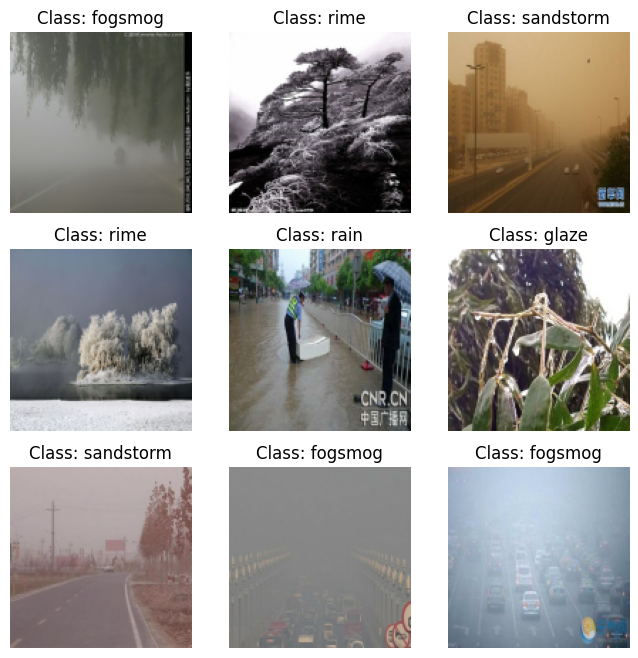

In [73]:
images, labels = next(iter(dataset.take(1)))
images = images.numpy()
labels = labels.numpy()

fig, ax = plt.subplots(3, 3, figsize=(8, 8))
indices = np.random.choice(range(images.shape[0]), size=9, replace=False)
for i, idx in enumerate(indices):
    row, col = divmod(i, 3)
    ax[row, col].imshow(images[idx].astype("uint8"))
    ax[row, col].axis("off")
    ax[row, col].set_title(f"Class: {class_names[labels[idx]]}")
plt.show()

In [74]:
dataset = dataset.map(lambda x, y: (x / 255.0, y))
num_classes = len(class_names)

### Διαχωρισμός δεδομένων.
Διαχωρισμός των εικονών για την χρήση τους σε Training, Validation και Testing.

In [85]:
Data_Size = len(dataset)

train_size = int(0.7 * Data_Size)
test_size = int(0.1 * Data_Size)
validation_size = Data_Size - train_size - test_size

train_dataset = dataset.take(train_size)
test_dataset = dataset.skip(train_size).take(test_size)
validation_dataset = dataset.skip(train_size + test_size).take(validation_size)

train_dataset = train_dataset.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

### Ορισμός baseline CNN
Δημιουργία απλού CNN για χρήση ως γραμμή βάσης. Χρησιμοποιούμε 3 Convolution Layers, 3 Pooling Layers καθώς και 2 Flatten και Dense. Για να βελτιώσω την αποδοτικότητα πρόσθεσα και Dropouts.

In [76]:
model = Sequential([
    Input(shape = (128, 128, 3)),

    #Conv1
    layers.Conv2D(32, (3, 3), activation = "relu", padding='same'),
    #Pool1
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    #Conv2
    layers.Conv2D(64, (3, 3), activation = "relu", padding='same'),
    #Pool2
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    #Conv3
    layers.Conv2D(128, (3, 3), activation = "relu", padding='same'),
    #Pool3
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    #Flatten
    layers.GlobalAveragePooling2D(),

    #Dense
    layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(0.0001)),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation = "softmax")
])

### Μεταγλώττιση μοντέλου
Ορισμός optimizer, loss και metrics για εκπαίδευση. Παρουίαση δεδομένων μοντέλου.

In [77]:
# Μεταγλώττιση του μοντέλου με optimizer, loss και metrics
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy",tf.keras.metrics.SparseCategoricalAccuracy(name='balanced_acc')]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 11)             │         2,827 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,099 (504.29 KB)

 Trainable params: 129,099 (504.29 KB)

 Non-trainable params: 0 (0.00 B)

In [78]:
epochs = 70
patience = 10
min_delta = 0.001

In [79]:
train_labels = list(dataset.map(lambda x, y: y).unbatch().as_numpy_iterator()) 

# Υπολογισμός βαρών
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# Μετατροπή σε λεξικό (dictionary) που θέλει το Keras
class_weights_dict = dict(enumerate(class_weights))

print("Βάρη ανά κλάση:", class_weights_dict)

2026-02-05 23:41:59.851770: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-02-05 23:42:00.171544: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-02-05 23:42:00.852332: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


Βάρη ανά κλάση: {0: np.float64(0.8937223235217504), 1: np.float64(0.7330413417369939), 2: np.float64(1.3133014354066985), 3: np.float64(0.976241286100441), 4: np.float64(1.055529918474081), 5: np.float64(1.6546901374487581), 6: np.float64(1.1859661251296232), 7: np.float64(2.688871473354232), 8: np.float64(0.5377742946708464), 9: np.float64(0.9014713610089332), 10: np.float64(1.0045381349729177)}


### Ορισμός Early Stopping
Χρησιμοποιούμε Early Stopping με patience 10 για να πετύχουμε μεγαλύτερο Accuracy.

In [80]:
early_stopping = EarlyStopping(
    monitor = "val_loss", 
    patience = patience, 
    min_delta = min_delta, 
    restore_best_weights = True,
    verbose = 1
)

### Εκτέλεση Μοντέλου.


In [81]:
# Εκπαίδευση του μοντέλου
history = model.fit(
    train_dataset,
    validation_data = validation_dataset,
    epochs = epochs,   
    callbacks = [early_stopping],
    class_weight=class_weights_dict
)

Epoch 1/50
 38/150 ━━━━━━━━━━━━━━━━━━━━ 13s 120ms/step - accuracy: 0.1294 - balanced_acc: 0.1294 - loss: 2.2886

2026-02-05 23:42:12.254618: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


 99/150 ━━━━━━━━━━━━━━━━━━━━ 6s 121ms/step - accuracy: 0.1669 - balanced_acc: 0.1669 - loss: 2.2623

2026-02-05 23:42:19.688568: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.1963 - balanced_acc: 0.1963 - loss: 2.2112

2026-02-05 23:42:26.627571: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-02-05 23:42:26.974342: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-02-05 23:42:28.258117: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


150/150 ━━━━━━━━━━━━━━━━━━━━ 23s 144ms/step - accuracy: 0.2685 - balanced_acc: 0.2685 - loss: 2.0702 - val_accuracy: 0.4245 - val_balanced_acc: 0.4245 - val_loss: 1.7870
Epoch 2/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 19s 128ms/step - accuracy: 0.4533 - balanced_acc: 0.4533 - loss: 1.6082 - val_accuracy: 0.4439 - val_balanced_acc: 0.4439 - val_loss: 1.5482
Epoch 3/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 19s 124ms/step - accuracy: 0.4954 - balanced_acc: 0.4954 - loss: 1.4600 - val_accuracy: 0.4964 - val_balanced_acc: 0.4964 - val_loss: 1.3954
Epoch 4/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 19s 123ms/step - accuracy: 0.5350 - balanced_acc: 0.5350 - loss: 1.3492 - val_accuracy: 0.5187 - val_balanced_acc: 0.5187 - val_loss: 1.3210
Epoch 5/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 19s 124ms/step - accuracy: 0.5381 - balanced_acc: 0.5381 - loss: 1.3158 - val_accuracy: 0.5173 - val_balanced_acc: 0.5173 - val_loss: 1.3156
Epoch 6/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 19s 124ms/step - accuracy: 0.5385 - balanced_acc: 0.5385 - loss: 1

### Οπτικοποίηση
Δημιουργία γραφημάτων (loss/accuracy). Μετά κάνουμε το τελευταίο Testing με τελικό accuracy ~83%. Πρόσθεσα και Confusion Matrix ώστε να δούμε ακριβώς τι δεδομένα χάνονται.

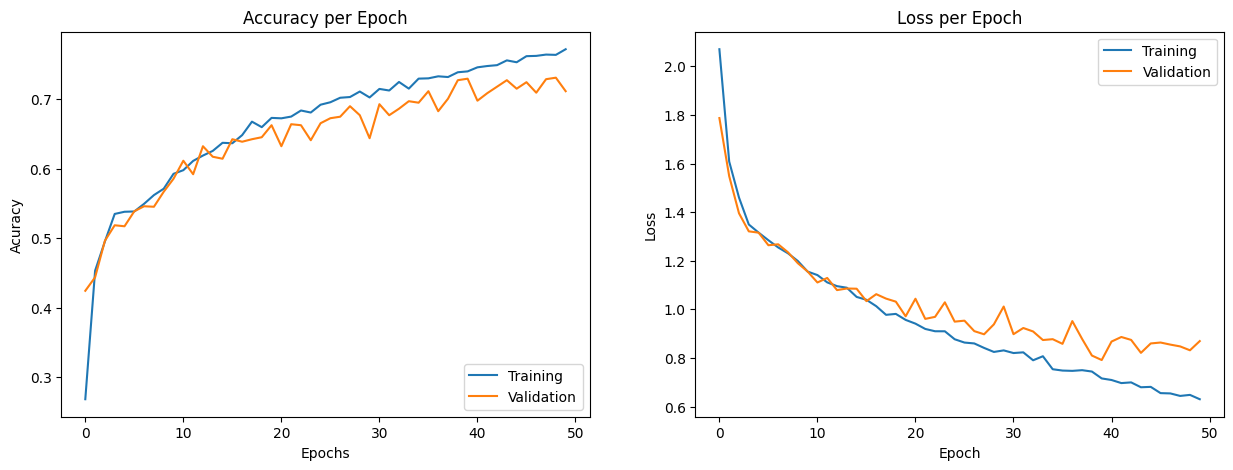

In [82]:
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

total_epochs = range(len(train_accuracy))

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(total_epochs, train_accuracy, label = "Training")
plt.plot(total_epochs, val_accuracy, label = "Validation")
plt.xlabel("Epochs")
plt.ylabel("Acuracy")
plt.legend(loc = "lower right")
plt.title("Accuracy per Epoch")

plt.subplot(1, 2, 2)
plt.plot(total_epochs, train_loss, label = "Training")
plt.plot(total_epochs, val_loss, label = "Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(loc = "upper right")
plt.title("Loss per Epoch")

plt.show()

In [83]:
# Αξιολόγηση του μοντέλου
results = model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

2026-02-05 23:58:10.257671: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile
2026-02-05 23:58:10.531352: W tensorflow/core/lib/png/png_io.cc:95] PNG warning: iCCP: known incorrect sRGB profile


21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7798 - balanced_acc: 0.7798 - loss: 0.6586
Test Loss: 1.0164
loss: 0.6586
compile_metrics: 0.7798


2026-02-05 23:58:17.684923: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


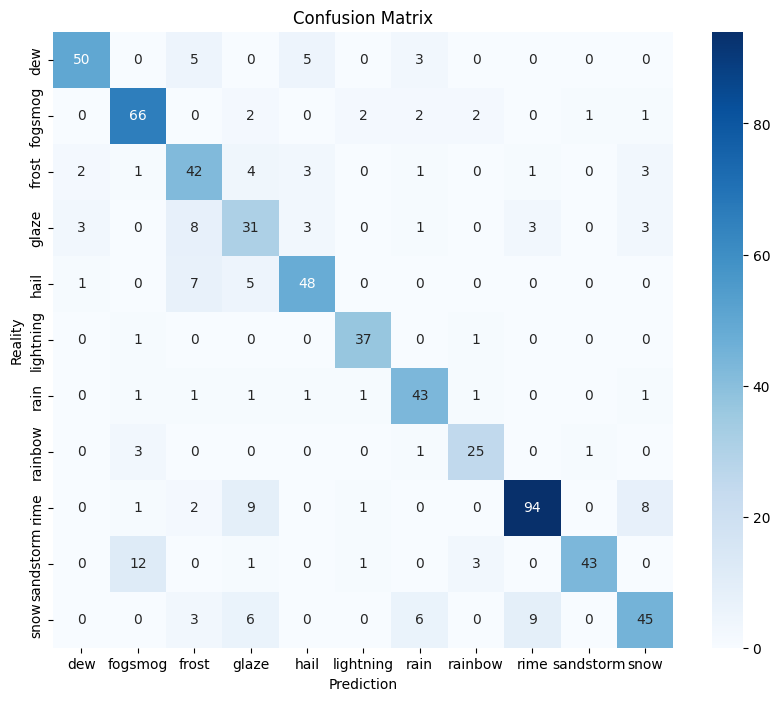


--- ΑΝΑΛΥΤΙΚΗ ΑΝΑΦΟΡΑ ΕΠΙΔΟΣΕΩΝ ---
              precision    recall  f1-score   support

         dew       0.89      0.79      0.84        63
     fogsmog       0.78      0.87      0.82        76
       frost       0.62      0.74      0.67        57
       glaze       0.53      0.60      0.56        52
        hail       0.80      0.79      0.79        61
   lightning       0.88      0.95      0.91        39
        rain       0.75      0.86      0.80        50
     rainbow       0.78      0.83      0.81        30
        rime       0.88      0.82      0.85       115
   sandstorm       0.96      0.72      0.82        60
        snow       0.74      0.65      0.69        69

    accuracy                           0.78       672
   macro avg       0.78      0.78      0.78       672
weighted avg       0.79      0.78      0.78       672



In [84]:
y_pred = []
y_true = []

for images, labels in test_dataset:
# Πρόβλεψη με το εκπαιδευμένο μοντέλο
    predictions = model.predict(images, verbose = 0)
    y_pred.extend(np.argmax(predictions, axis = 1))
    y_true.extend(labels.numpy())

conf_matrix = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot = True, fmt = "d", cmap = "Blues", xticklabels = class_names, yticklabels = class_names)

plt.xlabel("Prediction")
plt.ylabel("Reality")
plt.title("Confusion Matrix")
plt.show()

print("\n--- ΑΝΑΛΥΤΙΚΗ ΑΝΑΦΟΡΑ ΕΠΙΔΟΣΕΩΝ ---")
print(classification_report(y_true, y_pred, target_names=class_names))

## Επιπλέον περιγραφή MobileNetV2 (Transfer Learning)
Το **MobileNetV2** είναι ελαφριά αρχιτεκτονική με inverted residuals και linear bottlenecks, σχεδιασμένη για αποδοτικότητα σε κινητές/ενσωματωμένες συσκευές. Στο πλαίσιο **μεταφοράς μάθησης**, χρησιμοποιούμε το προεκπαιδευμένο backbone (σε ImageNet) ως εξαγωγέα χαρακτηριστικών και προσθέτουμε έναν μικρό ταξινομητή (GlobalAveragePooling + Dense) για τις δικές μας κλάσεις. Θα χρησιμοποιήσω αυτό το μοντέλο με τα προηγούμενα δεδομένα ως μέτρο σύγκρισης ενός προεκπαιδευμένου μοντέλου σε σχέση με το προηγούμενο.

### Εισαγωγή βιβλιοθηκών
Φόρτωση απαραίτητων βιβλιοθηκών και βοηθητικών συναρτήσεων.

In [26]:
# Εισαγωγή του MobileNetV2 με weights από ImageNet
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

# Φόρτωση του base model χωρίς τα top layers
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(128,128,3))
base_model.trainable = False 

In [27]:
# Προσθήκη custom top layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(num_classes, activation='softmax')(x)

model_mobilenet = Model(inputs=base_model.input, outputs=predictions)

### Ορισμός MobileNetV2 (Transfer Learning)
Φόρτωση προεκπαιδευμένου backbone και προσθήκη custom ταξινομητή.

In [28]:
# Μεταγλώττιση του μοντέλου MobileNetV2
model_mobilenet.compile(optimizer='adam', 
                        loss='sparse_categorical_crossentropy', 
                        metrics=['accuracy'])

In [29]:
# Εκπαίδευση του μοντέλου MobileNetV2
history_mobilenet = model_mobilenet.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
16/86 [====>.........................] - ETA: 12s - loss: 1.6557 - accuracy: 0.4697

2025-08-31 19:18:00.026771: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile


34/86 [==========>...................] - ETA: 9s - loss: 1.2373 - accuracy: 0.5915

2025-08-31 19:18:03.071880: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile


82/86 [===========================>..] - ETA: 0s - loss: 0.9042 - accuracy: 0.6905

...

82/86 [===========================>..] - ETA: 0s - loss: 0.0551 - accuracy: 0.9897

2025-08-31 19:21:59.102373: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile


86/86 [==============================] - ETA: 0s - loss: 0.0602 - accuracy: 0.9884

2025-08-31 19:22:02.395284: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile
2025-08-31 19:22:03.684396: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile
2025-08-31 19:22:07.196130: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile


86/86 [==============================] - 25s 289ms/step - loss: 0.0602 - accuracy: 0.9884 - val_loss: 0.4743 - val_accuracy: 0.8670


In [30]:
# Αξιολόγηση του μοντέλου MobileNetV2
loss_mobilenet, acc_mobilenet = model_mobilenet.evaluate(test_dataset)
print(f'Test accuracy: {acc_mobilenet*100:.2f}%')

2025-08-31 19:22:22.542016: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile
2025-08-31 19:22:23.832331: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile


 5/11 [============>.................] - ETA: 1s - loss: 0.2501 - accuracy: 0.9500

2025-08-31 19:22:27.600444: W tensorflow/core/lib/png/png_io.cc:88] PNG warning: iCCP: known incorrect sRGB profile


11/11 [==============================] - 8s 176ms/step - loss: 0.2931 - accuracy: 0.9247
Test accuracy: 92.47%


In [31]:
import matplotlib.pyplot as plt

def plot_history(history):
    # Accuracy
    plt.plot(history.history['accuracy'], label='train_accuracy')
    plt.plot(history.history['val_accuracy'], label='val_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    # Loss
    plt.plot(history.history['loss'], label='train_loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()


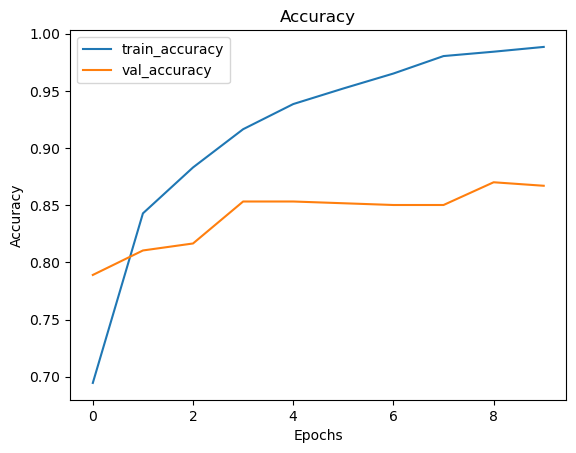

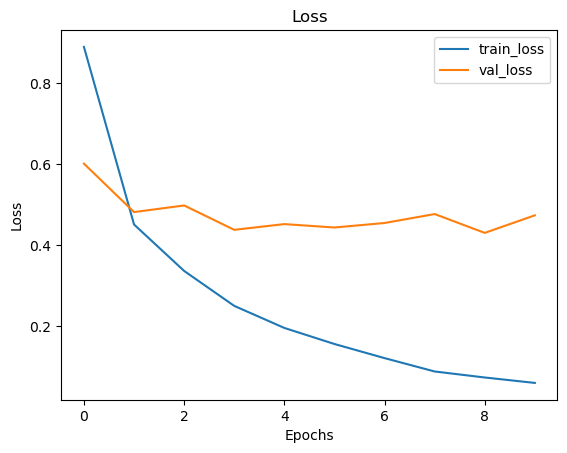

In [32]:
plot_history(history_mobilenet)

## Συμπεράσματα
Όπως φαίνεται, το Pre-trained μοντέλο πετυχαίνει Accuracy ~90%-92%. Είναι φανερό πως το δικό μου μοντέλο χρειάζεται ακόμα επιπλέον Fine Tuning και βελτιώσεις. Π.χ. επιπλέον layers, και αλλαγες στα parameters.